# EDA: Customer Propensity to Purchase

Análise exploratória do dataset processado pelo ETL (`make etl`), para orientar a
modelagem de propensão de compra.

**Perguntas que o notebook responde**

1. Os dados estão íntegros e prontos para modelagem?
2. Qual o tamanho do desbalanceamento e o que isso muda na avaliação?
3. Quais comportamentos mais se associam a fazer um pedido?
4. Há vazamento (features que só existem porque a compra aconteceu)?
5. Que conjunto de features, validação e métricas usar no treino?

Pré-requisito: `make etl` (gera `data/processed/customer_propensity.parquet`).

## Sumário executivo

| Tema | Achado | Decisão para a modelagem |
| --- | --- | --- |
| Qualidade | 455.401 usuários, sem nulos, `user_id` único, todas as flags 0/1 | Nenhuma limpeza necessária |
| Alvo | 4,19% de pedidos (19.093) | Split e CV estratificados; PR-AUC como métrica principal |
| Padrões | Só 9.086 combinações distintas de flags | Dados quase tabulares de "tipos de visita"; modelos simples bastam |
| Funil | 100% dos pedidos passaram por `saw_checkout` | O checkout é condição necessária do pedido |
| Vazamento | `checked_delivery_detail`, `saw_checkout` e `sign_in` têm AUC univariada > 0,97 | Cenário principal sem essas 3 features |
| Ganho real | Sem o fim do funil, PR-AUC cai de ~0,91 para ~0,37-0,41 (base: 0,04) | É essa a dificuldade honesta do problema |
| Contexto | Desktop converte 1,6x mais que mobile; usuário recorrente 1,8x mais que novo | Manter flags de contexto |

Os números do sumário são recalculados nas seções abaixo (seed fixa).

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Jupyter e VS Code rodam o notebook a partir de notebooks/; a raiz do projeto
# entra no path para importar `src`.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, norm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.config import PROCESSED_DATA_FILE

SEED = 42
TARGET = "ordered"
ID_COLUMN = "user_id"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4.5)})
pd.set_option("display.float_format", "{:.4f}".format)

if not PROCESSED_DATA_FILE.exists():
    raise FileNotFoundError(f"{PROCESSED_DATA_FILE} não existe. Rode `make etl` antes.")

df = pd.read_parquet(PROCESSED_DATA_FILE)
target = df[TARGET]
features = df.drop(columns=[ID_COLUMN, TARGET])
df.shape

(455401, 25)

As 23 features são agrupadas por natureza. A distinção importa na seção de
vazamento: o fim do funil acontece junto com a compra.

In [3]:
FEATURE_GROUPS: dict[str, list[str]] = {
    "fim do funil": ["sign_in", "saw_checkout", "checked_delivery_detail"],
    "carrinho": [
        "basket_icon_click",
        "basket_add_list",
        "basket_add_detail",
        "closed_minibasket_click",
    ],
    "navegação": [
        "saw_homepage",
        "list_size_dropdown",
        "sort_by",
        "image_picker",
        "promo_banner_click",
        "detail_wishlist_add",
        "account_page_click",
        "checked_returns_detail",
        "saw_delivery",
        "saw_sizecharts",
        "saw_account_upgrade",
    ],
    "contexto": ["device_mobile", "device_computer", "device_tablet", "returning_user", "loc_uk"],
}
GROUP_OF = {feature: group for group, cols in FEATURE_GROUPS.items() for feature in cols}
PALETTE = dict(zip(FEATURE_GROUPS, sns.color_palette("deep", len(FEATURE_GROUPS)), strict=True))
LEGEND_HANDLES = [plt.Rectangle((0, 0), 1, 1, color=color) for color in PALETTE.values()]

assert set(GROUP_OF) == set(features.columns), "Grupo faltando para alguma feature"

## 2. Visão geral e schema

In [4]:
memory_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]} | Memória: {memory_mb:.1f} MB")
df.dtypes.value_counts()

Linhas: 455,401 | Colunas: 25 | Memória: 30.5 MB


bool    24
str      1
Name: count, dtype: int64

In [5]:
df.head()

,user_id,basket_icon_click,basket_add_list,basket_add_detail,sort_by,image_picker,account_page_click,promo_banner_click,detail_wishlist_add,list_size_dropdown,...,saw_sizecharts,saw_delivery,saw_account_upgrade,saw_homepage,device_mobile,device_computer,device_tablet,returning_user,loc_uk,ordered
0,a720-6b732349-a720-4862-bd21-644732,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,a0c0-6b73247c-a0c0-4bd9-8baa-797356,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2,86a8-6b735c67-86a8-407b-ba24-333055,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,True,False
3,6a3d-6b736346-6a3d-4085-934b-396834,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,True,False
4,b74a-6b737717-b74a-45c3-8c6a-421140,False,True,False,True,False,False,False,False,True,...,False,False,False,True,False,False,True,False,True,True


## 3. Qualidade dos dados

In [6]:
quality = pd.Series(
    {
        "nulos (total)": int(df.isna().sum().sum()),
        "user_id duplicado": int(df[ID_COLUMN].duplicated().sum()),
        "colunas não booleanas (exceto id)": int(
            (~df.drop(columns=ID_COLUMN).dtypes.map(pd.api.types.is_bool_dtype)).sum()
        ),
        "combinações distintas de flags": len(features.drop_duplicates()),
        "linhas repetindo uma combinação já vista": int(features.duplicated().sum()),
    }
)
quality.to_frame("valor")

,valor
nulos (total),0
user_id duplicado,0
colunas não booleanas (exceto id),0
combinações distintas de flags,9086
linhas repetindo uma combinação já vista,446315


**Leitura.** Não há nulos nem ids repetidos, e o ETL já garantiu flags booleanas.
O ponto que chama atenção: 455 mil usuários cabem em só **9.086 combinações**
de flags. Cada linha é um usuário distinto, então repetir a combinação não é
duplicata a remover; significa que o problema é, na prática, aprender a taxa de
pedido de alguns milhares de "tipos de visita". Isso favorece modelos simples e
estáveis.

Os dispositivos não são mutuamente exclusivos: alguns usuários usaram mais de um
no mesmo dia.

In [7]:
devices = ["device_mobile", "device_computer", "device_tablet"]
features[devices].sum(axis=1).value_counts().rename_axis("nº de dispositivos").to_frame("usuários")

,usuários
nº de dispositivos,
1,453924
2,1456
3,21


## 4. Alvo: `ordered`

,usuários,%
ordered,,
False,436308,95.8074
True,19093,4.1926


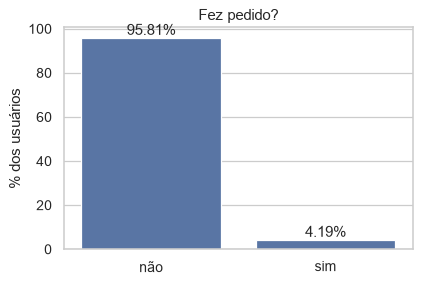

In [8]:
target_summary = target.value_counts().to_frame("usuários")
target_summary["%"] = target_summary["usuários"] / len(target) * 100
display(target_summary)

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.barplot(x=target_summary.index.map({False: "não", True: "sim"}), y=target_summary["%"], ax=ax)
ax.set(title="Fez pedido?", xlabel="", ylabel="% dos usuários")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
plt.show()

**Leitura.** 4,19% de positivos. Consequências diretas:

- Um modelo que sempre responde "não compra" acerta 95,8%: acurácia não serve.
- A linha de base da PR-AUC é a própria prevalência (~0,042), não 0,5.
- Split de treino/teste e validação cruzada precisam ser **estratificados**.
- Para o negócio, o que importa é o ranking: quantos compradores aparecem nos
  primeiros k% de usuários ordenados por propensão (precision@k e lift).

## 5. Análise univariada: frequência de cada comportamento

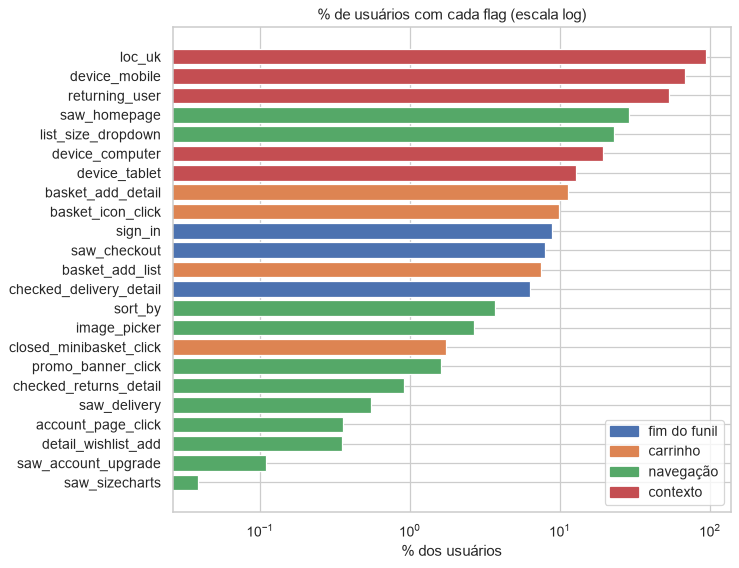

In [9]:
prevalence = features.mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(prevalence.index, prevalence * 100, color=prevalence.index.map(GROUP_OF).map(PALETTE))
ax.set_xscale("log")
ax.set(title="% de usuários com cada flag (escala log)", xlabel="% dos usuários")
ax.legend(LEGEND_HANDLES, FEATURE_GROUPS, loc="lower right")
plt.show()

In [10]:
rare = prevalence[prevalence < 0.01].to_frame("prevalência")
rare["usuários"] = (rare["prevalência"] * len(df)).round().astype(int)
rare

,prevalência,usuários
saw_sizecharts,0.0004,177
saw_account_upgrade,0.0011,499
detail_wishlist_add,0.0035,1599
account_page_click,0.0036,1626
saw_delivery,0.0055,2524
checked_returns_detail,0.0092,4180


**Leitura.** A distribuição é muito assimétrica: `loc_uk` (93%) e `device_mobile`
(68%) estão em quase todos, enquanto 7 flags aparecem em menos de 1% dos
usuários. `saw_sizecharts` tem só ~180 casos. Para as flags raras, qualquer taxa
de conversão vem com incerteza grande; por isso a próxima seção traz intervalos
de confiança.

## 6. Análise bivariada: cada comportamento contra o pedido

In [11]:
def wilson_interval(successes: int, total: int, confidence: float = 0.95) -> tuple[float, float]:
    # Intervalo de Wilson: estável para proporções pequenas e amostras pequenas.
    z = norm.ppf(1 - (1 - confidence) / 2)
    p = successes / total
    center = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return center - margin, center + margin


def association_row(feature: pd.Series) -> dict[str, float]:
    with_flag = target[feature]
    low, high = wilson_interval(int(with_flag.sum()), len(with_flag))
    return {
        "prevalência": feature.mean(),
        "P(pedido | flag=1)": with_flag.mean(),
        "IC95% inf": low,
        "IC95% sup": high,
        "P(pedido | flag=0)": target[~feature].mean(),
        "lift": with_flag.mean() / target.mean(),
        "phi": np.corrcoef(feature, target)[0, 1],
        "AUC univariada": roc_auc_score(target, feature),
        "p-valor qui²": chi2_contingency(pd.crosstab(feature, target))[1],
    }


association = pd.DataFrame({name: association_row(col) for name, col in features.items()}).T
association["informação mútua"] = mutual_info_classif(
    features, target, discrete_features=True, random_state=SEED
)
association.insert(0, "grupo", association.index.map(GROUP_OF))
association = association.sort_values("phi", ascending=False)
association

,grupo,prevalência,P(pedido | flag=1),IC95% inf,IC95% sup,P(pedido | flag=0),lift,phi,AUC univariada,p-valor qui²,informação mútua
checked_delivery_detail,fim do funil,0.0629,0.6599,0.6544,0.6654,0.0005,15.7407,0.7987,0.9837,0.0000,0.1300
saw_checkout,fim do funil,0.0801,0.5235,0.5184,0.5286,0.0000,12.4867,0.7090,0.9801,0.0000,0.1186
sign_in,fim do funil,0.0888,0.4692,0.4643,0.4741,0.0003,11.1910,0.6656,0.9723,0.0000,0.1103
basket_icon_click,carrinho,0.0991,0.3007,0.2965,0.3049,0.0134,7.1719,0.4283,0.8194,0.0000,0.0492
basket_add_detail,carrinho,0.1129,0.2747,0.2709,0.2786,0.0123,6.5527,0.4144,0.8272,0.0000,0.0488
basket_add_list,carrinho,0.0745,0.2451,0.2406,0.2497,0.0256,5.8461,0.2877,0.6885,0.0000,0.0224
saw_homepage,navegação,0.2900,0.0914,0.0899,0.0930,0.0217,2.1801,0.1578,0.6786,0.0000,0.0110
list_size_dropdown,navegação,0.2304,0.0987,0.0969,0.1005,0.0249,2.3532,0.1549,0.6627,0.0000,0.0100
closed_minibasket_click,carrinho,0.0173,0.2536,0.2441,0.2633,0.0382,6.0478,0.1400,0.5455,0.0000,0.0048
image_picker,navegação,0.0267,0.1284,0.1226,0.1344,0.0396,3.0620,0.0715,0.5288,0.0000,0.0017


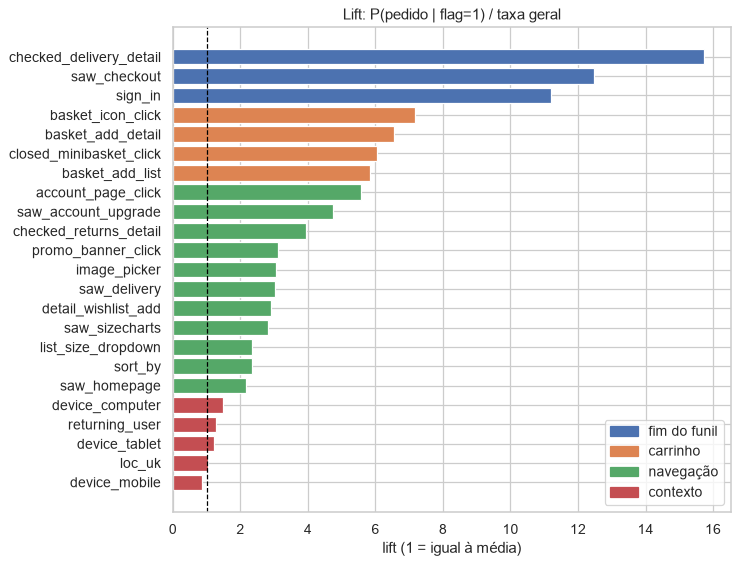

In [12]:
fig, ax = plt.subplots(figsize=(8, 7))
lift_order = association.sort_values("lift")
ax.barh(lift_order.index, lift_order["lift"], color=lift_order["grupo"].map(PALETTE))
ax.axvline(1, color="black", linewidth=1, linestyle="--")
ax.set(title="Lift: P(pedido | flag=1) / taxa geral", xlabel="lift (1 = igual à média)")
ax.legend(LEGEND_HANDLES, FEATURE_GROUPS, loc="lower right")
plt.show()

**Leitura.**

- Todas as associações são estatisticamente significativas (maior p-valor do
  qui²: ~1e-6, em `saw_sizecharts`).
  Com 455 mil linhas isso é esperado e diz pouco; o que importa é o tamanho do
  efeito (phi, lift, informação mútua).
- **Fim do funil domina:** `checked_delivery_detail` (phi 0,80), `saw_checkout`
  (0,71) e `sign_in` (0,67) têm AUC univariada acima de 0,97. Uma única flag
  quase resolve o problema, sinal clássico de vazamento (seção 8).
- **Carrinho** é o melhor sinal de intenção legítimo: `basket_icon_click` e
  `basket_add_detail` multiplicam a chance de pedido por 6,5x a 7,2x.
- **Navegação** tem lifts altos em flags raras (`account_page_click` 5,6x), mas
  os intervalos de confiança são largos e o efeito no total é pequeno.
- **Contexto:** `device_mobile` é o único fator de redução (lift 0,86);
  `returning_user` tem lift 1,27 (5,3% contra 2,9% dos novos).

## 7. Funil de conversão

,usuários,% do total,% da etapa anterior
visitou,455401,100.0000,NaN
adicionou ao carrinho,68621,15.0683,15.0683
abriu o carrinho,45153,9.9150,65.8006
fez login,40444,8.8810,89.5710
viu o checkout,36471,8.0085,90.1765
conferiu a entrega,28633,6.2874,78.5090
fez pedido,19093,4.1926,66.6818


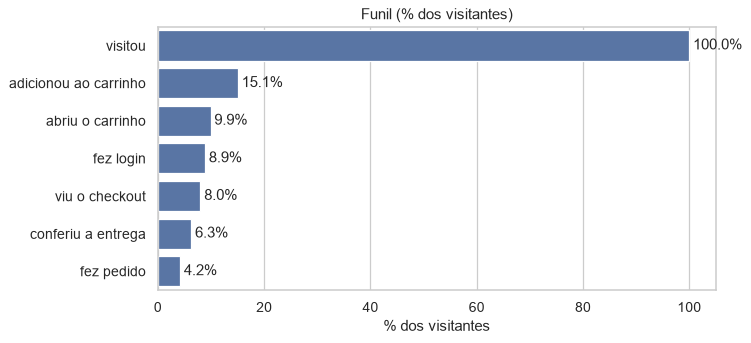

In [13]:
funnel = pd.Series(
    {
        "visitou": len(df),
        "adicionou ao carrinho": int(
            (features["basket_add_list"] | features["basket_add_detail"]).sum()
        ),
        "abriu o carrinho": int(features["basket_icon_click"].sum()),
        "fez login": int(features["sign_in"].sum()),
        "viu o checkout": int(features["saw_checkout"].sum()),
        "conferiu a entrega": int(features["checked_delivery_detail"].sum()),
        "fez pedido": int(target.sum()),
    }
).to_frame("usuários")
funnel["% do total"] = funnel["usuários"] / len(df) * 100
funnel["% da etapa anterior"] = funnel["usuários"].pct_change().add(1).mul(100)
display(funnel)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=funnel["% do total"], y=funnel.index, ax=ax, color=sns.color_palette("deep")[0])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Funil (% dos visitantes)", xlabel="% dos visitantes", ylabel="")
plt.show()

In [14]:
necessary = pd.Series(
    {
        "pedidos sem ver o checkout": int((target & ~features["saw_checkout"]).sum()),
        "pedidos sem conferir a entrega": int(
            (target & ~features["checked_delivery_detail"]).sum()
        ),
        "pedidos sem login": int((target & ~features["sign_in"]).sum()),
        "pedidos sem adicionar ao carrinho": int(
            (target & ~(features["basket_add_list"] | features["basket_add_detail"])).sum()
        ),
        "viram o checkout e não pediram": int((~target & features["saw_checkout"]).sum()),
    }
).to_frame("usuários")
necessary["% dos pedidos"] = necessary["usuários"] / target.sum() * 100
necessary

,usuários,% dos pedidos
pedidos sem ver o checkout,0,0.0000
pedidos sem conferir a entrega,197,1.0318
pedidos sem login,117,0.6128
pedidos sem adicionar ao carrinho,2076,10.8731
viram o checkout e não pediram,17378,91.0177


As etapas não são estritamente aninhadas (dá para abrir o carrinho sem adicionar
item no mesmo dia, por exemplo), então o funil é uma aproximação da jornada.

**Leitura.** Nenhum pedido aconteceu sem `saw_checkout`: ver o checkout é
**condição necessária** do pedido. Login e conferência da entrega ficam perto
disso (menos de 1,1% dos pedidos sem eles). Já o carrinho não é: ~11% dos
pedidos não registraram `basket_add_*`, provavelmente compras por outro caminho
(ex.: "comprar agora"), o que é um bom motivo para não usar regras manuais.

Quase metade de quem chega ao checkout não compra (47,6%, 17.378 usuários). Esse grupo é o
alvo natural de campanhas de recuperação de carrinho.

## 8. Vazamento: o que o modelo pode saber no momento da previsão

A pergunta de negócio decide quais features são legítimas. O objetivo é achar
visitantes com intenção de compra **antes** de eles comprarem (para remarketing,
cupom, priorização). Quem já está no checkout praticamente já decidiu; prever
"compra" a partir do checkout é medir o próprio desfecho.

O experimento abaixo compara três conjuntos de features com validação cruzada
estratificada (5 folds, mesma seed) e dois modelos de famílias diferentes.

In [15]:
LEAKY_CORE = ["saw_checkout", "checked_delivery_detail"]
FEATURE_SETS: dict[str, list[str]] = {
    "todas (23)": list(features.columns),
    "sem checkout/entrega (21)": [c for c in features if c not in LEAKY_CORE],
    "sem fim do funil (20)": [c for c in features if GROUP_OF[c] != "fim do funil"],
}
MODELS = {
    "regressão logística": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_scores(columns: list[str], model: object) -> dict[str, float]:
    scores = cross_validate(
        model, features[columns], target, cv=cv, scoring=["roc_auc", "average_precision"]
    )
    return {
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_average_precision"].mean(),
    }


leakage = pd.DataFrame(
    [
        {"features": set_name, "modelo": model_name, **cv_scores(cols, model)}
        for set_name, cols in FEATURE_SETS.items()
        for model_name, model in MODELS.items()
    ]
)
leakage

,features,modelo,ROC-AUC,PR-AUC
0,todas (23),regressão logística,0.9974,0.9038
1,todas (23),gradient boosting,0.9975,0.9087
2,sem checkout/entrega (21),regressão logística,0.9861,0.6679
3,sem checkout/entrega (21),gradient boosting,0.9870,0.6819
4,sem fim do funil (20),regressão logística,0.9461,0.3740
5,sem fim do funil (20),gradient boosting,0.9514,0.4081


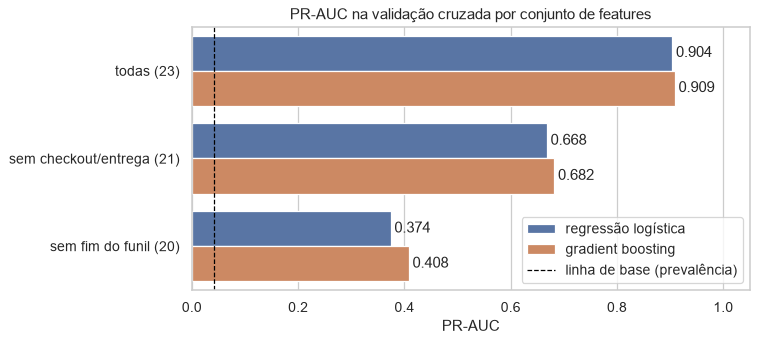

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=leakage, x="PR-AUC", y="features", hue="modelo", ax=ax)
ax.axvline(
    target.mean(), color="black", linestyle="--", linewidth=1, label="linha de base (prevalência)"
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
ax.set(title="PR-AUC na validação cruzada por conjunto de features", ylabel="", xlim=(0, 1.05))
ax.legend(loc="lower right")
plt.show()

**Leitura.**

- Com todas as features, ROC-AUC 0,997 e PR-AUC ~0,91: o modelo só reconhece
  quem já está no checkout. Não generaliza para o uso de negócio.
- Tirando checkout e entrega, a PR-AUC cai para ~0,67-0,68, mas `sign_in` ainda
  carrega boa parte do desfecho (89% dos logins chegam ao checkout).
- Sem o fim do funil, a PR-AUC fica em ~0,37-0,41, ainda **9x a linha de base**.
  Esse é o desempenho honesto de "intenção de compra" a partir de carrinho,
  navegação e contexto.
- Os dois modelos empatam em todos os cenários: a relação é quase aditiva e o
  boosting não encontra interações relevantes. Regressão logística é uma linha
  de base forte e interpretável.

**Decisão recomendada:** cenário principal **sem o fim do funil**
(`sign_in`, `saw_checkout`, `checked_delivery_detail`). O cenário com todas as
features fica registrado no MLflow só como teto de referência.

## 9. Correlação e redundância entre features

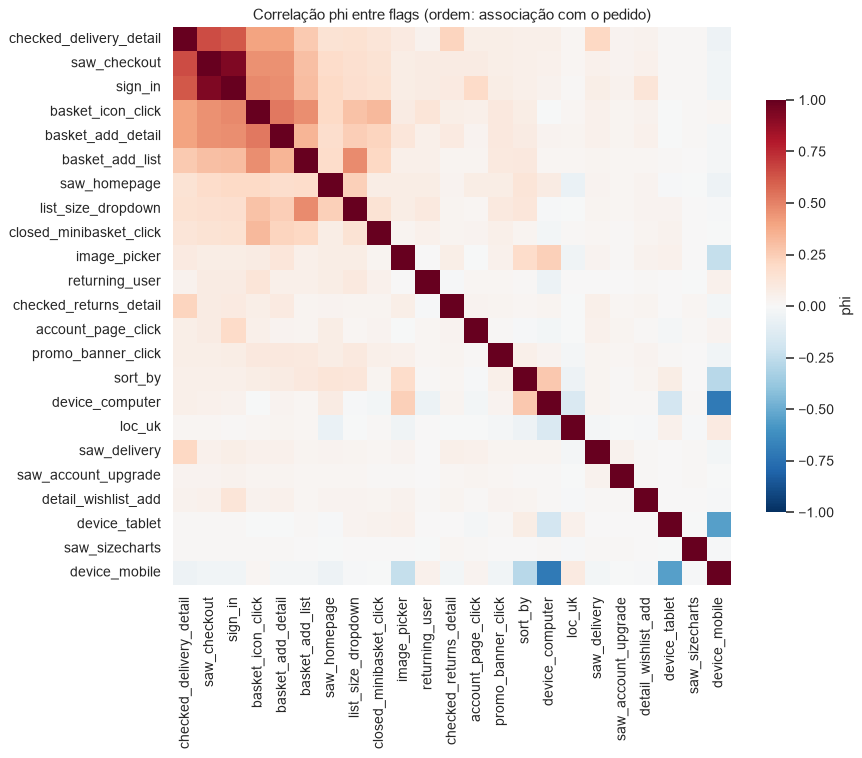

In [17]:
phi_matrix = features.astype("int8").corr()
order = association.index
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(
    phi_matrix.loc[order, order],
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"shrink": 0.7, "label": "phi"},
    ax=ax,
)
ax.set_title("Correlação phi entre flags (ordem: associação com o pedido)")
plt.show()

In [18]:
upper = phi_matrix.where(np.triu(np.ones(phi_matrix.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("phi").to_frame()
pairs["|phi|"] = pairs["phi"].abs()
pairs.sort_values("|phi|", ascending=False).head(10).drop(columns="|phi|")

phi
sign_in                 saw_checkout        0.9300
device_mobile           device_computer    -0.7067
checked_delivery_detail saw_checkout        0.6531
                        sign_in             0.6217
device_mobile           device_tablet      -0.5533
basket_icon_click       basket_add_detail   0.5299
                        sign_in             0.4788
basket_add_list         list_size_dropdown  0.4696
basket_icon_click       basket_add_list     0.4667
basket_add_detail       sign_in             0.4617

**Leitura.** O bloco do fim do funil é fortemente correlacionado entre si, o que
reforça que as três flags medem a mesma etapa. Os dispositivos têm correlação
negativa forte (`device_mobile` x `device_computer` -0,71), como esperado: quase todo
usuário tem exatamente um dispositivo, então as três flags somam ~1 e ficam
quase colineares com o intercepto. A regularização L2 padrão da regressão
logística lida com isso; para interpretar coeficientes, vale deixar uma delas
(ex.: `device_tablet`) como referência. Fora isso não há redundância que
justifique remover features.

## 10. Segmentos: dispositivo, recorrência e localização

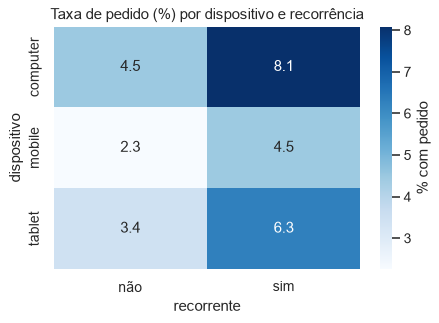

,taxa,usuários
loc_uk,,
False,0.0182,30410
True,0.0436,424991


In [19]:
main_device = np.select(
    [features["device_computer"], features["device_tablet"], features["device_mobile"]],
    ["computer", "tablet", "mobile"],
    default="nenhum",
)
segments = (
    df.assign(
        dispositivo=main_device,
        recorrente=features["returning_user"].map({True: "sim", False: "não"}),
    )
    .pivot_table(index="dispositivo", columns="recorrente", values=TARGET, aggfunc="mean")
    .mul(100)
)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
sns.heatmap(
    segments, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% com pedido"}, ax=ax
)
ax.set_title("Taxa de pedido (%) por dispositivo e recorrência")
plt.show()

df.groupby("loc_uk")[TARGET].agg(taxa="mean", usuários="size")

**Leitura.** O efeito de dispositivo e recorrência se soma: usuário recorrente
no computador converte 8,1%, contra 2,3% do novo no celular (3,5x). Para usuários com mais de
um dispositivo, o "principal" segue a prioridade computer > tablet > mobile.
Usuários fora do Reino Unido (7%) convertem menos da metade (1,8% contra 4,4%).
São sinais fracos isoladamente, mas úteis para ordenar quem não chegou ao
carrinho.

## 11. Padrões repetidos e limite de desempenho

In [20]:
def bayes_error(columns: list[str]) -> float:
    # Erro mínimo de qualquer classificador que só vê estas colunas (in-sample).
    rate = df.groupby(columns, observed=True)[TARGET].agg(["mean", "size"])
    return float((rate["size"] * np.minimum(rate["mean"], 1 - rate["mean"])).sum() / len(df))


limits = pd.DataFrame(
    {
        "combinações distintas": [
            len(features[cols].drop_duplicates()) for cols in FEATURE_SETS.values()
        ],
        "erro de Bayes (in-sample)": [bayes_error(cols) for cols in FEATURE_SETS.values()],
    },
    index=FEATURE_SETS.keys(),
)
limits["erro de quem sempre diz 'não'"] = target.mean()
limits

,combinações distintas,erro de Bayes (in-sample),erro de quem sempre diz 'não'
todas (23),9086,0.0060,0.0419
sem checkout/entrega (21),6638,0.0251,0.0419
sem fim do funil (20),4948,0.0390,0.0419


**Leitura.** Com as 23 features, o erro mínimo possível é ~0,6%: o desfecho é
quase determinístico dado o padrão de navegação, outra evidência do vazamento.
Sem o fim do funil, o erro mínimo sobe para ~3,9%, quase igual aos 4,19% de
quem sempre responde "não": nenhum padrão de intenção garante a compra, porque
usuários com o mesmo comportamento às vezes compram e às vezes não. Por isso
acurácia não mede nada aqui, e o valor do modelo está em **ordenar** os
usuários por probabilidade (PR-AUC, precision@k), não em classificar.

Como cada combinação se repete muitas vezes, os folds de CV compartilham
padrões. Isso não é vazamento (são usuários diferentes), mas faz as métricas de
treino e validação ficarem próximas; diferença grande entre elas indicaria bug.

## 12. Conclusões e decisões para a modelagem

| Tema | Decisão | Motivo |
| --- | --- | --- |
| Limpeza | Nenhuma remoção de linhas | Sem nulos, ids únicos, padrões repetidos são usuários distintos |
| Features | Cenário principal sem `sign_in`, `saw_checkout`, `checked_delivery_detail` | Fim do funil acontece junto com a compra (vazamento) |
| Referência | Rodar também com todas as features, só como teto | Mostrar no MLflow o efeito do vazamento |
| Pré-processamento | Nenhum escalonamento ou encoding | Todas as features já são booleanas |
| Split | Holdout estratificado (ex.: 80/20) + CV estratificada de 5 folds, seed 42 | 4,19% de positivos |
| Desbalanceamento | `class_weight="balanced"` ou ajuste de threshold, sem oversampling | Padrões repetidos tornam SMOTE pouco útil |
| Métricas | PR-AUC (principal), ROC-AUC, precision/recall@top 10%, lift | Acurácia é enganosa com 4% de positivos |
| Modelos | Regressão logística (baseline) e um modelo de árvore (RF ou boosting) | Empate na EDA indica relação quase aditiva |
| Threshold | Escolher pelo custo de negócio (ex.: orçamento de campanha = top k%) | O uso é ranqueamento, não classificação |

**Limitações do dataset:** loja fictícia, um único dia de visitas (sem
sazonalidade nem validação temporal) e só flags binárias (sem tempo de
sessão ou valor de carrinho). Os resultados servem para demonstrar o pipeline,
não para estimar desempenho em produção.